# Data audit: UNAM blade-coated perovskite films

Before any modelling, we audit the published archive of UV–vis absorption spectra of blade-coated perovskite thin films
([Abrego Martínez & Corpus Mendoza, Zenodo, 2026](https://doi.org/10.5281/zenodo.19237616), CC BY 4.0).
The audit answers four questions:

1. **Missingness** — which wavelengths were measured for which films, and is the missing-data pattern explainable?
2. **Values** — are the optical-density curves physically plausible (non-negative, varying, no degenerate shapes)?
3. **Parameters** — are the per-film fabrication variables complete enough to condition on later?
4. **Population** — what population do the 517 films actually form (substrates, additive chemistry, fabrication dates), so that any modelling statement names its population explicitly.

Terminology: the archive stores optical density, `OD(λ) = A(λ)/t` with thickness `t` in nm — units of nm⁻¹, *not* absorbance itself. We keep the archive's curves as shipped; preprocessing decisions come after the audit. Provenance and licences: [`data/README.md`](../data/README.md).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

from absynth.audit import (
    ADDITIVES_COLUMN,
    DATE_COLUMN,
    ODINT_PRIMARY,
    SUBSTRATE_STACK_COLUMN,
    audit_dataset,
    subset_min_observations,
)
from absynth.explore import nearest_neighbour_distances, pca_explained_variance
from absynth.loader import load_dataset

DATA_DIR = Path("../data/raw/Dataset")

In [2]:
dataset = load_dataset(DATA_DIR)
curves = dataset.curves
values = curves.optical_density
wavelengths = curves.wavelengths_nm
print(f"{curves.n_samples} films × {curves.n_wavelengths} wavelengths, "
      f"{wavelengths[0]:.0f}–{wavelengths[-1]:.0f} nm at {np.diff(wavelengths)[0]:.0f} nm")

517 films × 351 wavelengths, 300–1000 nm at 2 nm


The loader enforced the structural contract on read: uniform ascending wavelength grid, unique sample identifiers, and an exact one-to-one correspondence between curve columns and database rows.

## Integrity summary

In [3]:
report = audit_dataset(dataset)
pd.Series(report.summary).to_frame("value")

,value
n_samples,517
n_wavelengths,351
grid_start_nm,300.0
grid_end_nm,1000.0
grid_step_nm,2.0
grid_points_measured,179067
grid_points_missing,2400
n_curves_complete,469
n_curves_with_missing,48
n_starts_late,0


The per-film table behind the summary (one row per film):

In [4]:
diag = report.curve_diagnostics
diag.describe().T

,count,mean,std,min,25%,50%,75%,max
n_measured,517.0,346.357834,14.524692,301.000000,351.000000,351.000000,351.000000,351.000000
n_missing,517.0,4.642166,14.524692,0.000000,0.000000,0.000000,0.000000,50.000000
first_measured_nm,517.0,300.000000,0.000000,300.000000,300.000000,300.000000,300.000000,300.000000
last_measured_nm,517.0,990.715667,29.049383,900.000000,1000.000000,1000.000000,1000.000000,1000.000000
od_min,517.0,0.000927,0.000506,0.000114,0.000630,0.000817,0.001112,0.004634
od_max,517.0,0.010340,0.005411,0.002015,0.006723,0.009015,0.012646,0.031664
n_negative,517.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


How many films fall into each diagnostic category:

In [5]:
categories = {
    "ends early (truncated)": diag["ends_early"],
    "starts late": diag["starts_late"],
    "interior gap": diag["has_interior_gap"],
    "empty": diag["is_empty"],
    "has negative values": diag["n_negative"] > 0,
    "flat": diag["is_flat"],
    "all-zero": diag["is_zero"],
}
pd.DataFrame({name: mask.sum() for name, mask in categories.items()},
             index=["films"]).T

,films
ends early (truncated),48
starts late,0
interior gap,0
empty,0
has negative values,0
flat,0
all-zero,0


## Missingness structure

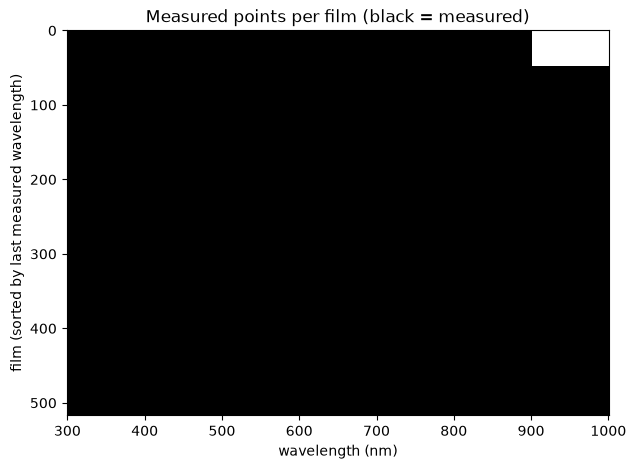

last_measured_nm
900.0    48


In [6]:
# Films sorted by their last measured wavelength: truncation, if any,
# appears as a clean block rather than scattered holes. Plotted in
# wavelength units; black marks measured points, white = unmeasured.
order = np.argsort(diag["last_measured_nm"].to_numpy(), kind="stable")
measured = np.isfinite(values[order])

plt.figure(figsize=(7, 5))
plt.imshow(measured, aspect="auto", interpolation="nearest", cmap="Greys",
           extent=[wavelengths[0] - 1, wavelengths[-1] + 1, len(order), 0])
plt.xlabel("wavelength (nm)")
plt.ylabel("film (sorted by last measured wavelength)")
plt.title("Measured points per film (black = measured)")
plt.show()

last = diag.loc[diag["last_measured_nm"] < wavelengths[-1], "last_measured_nm"]
print(last.value_counts().to_string())

## What the curves look like

One curve per film for the thinnest, thickest and three intermediate-thickness films. The thickness range spans roughly an order of magnitude, and the archive's `OD = A/t` normalization is what makes such different films comparable.

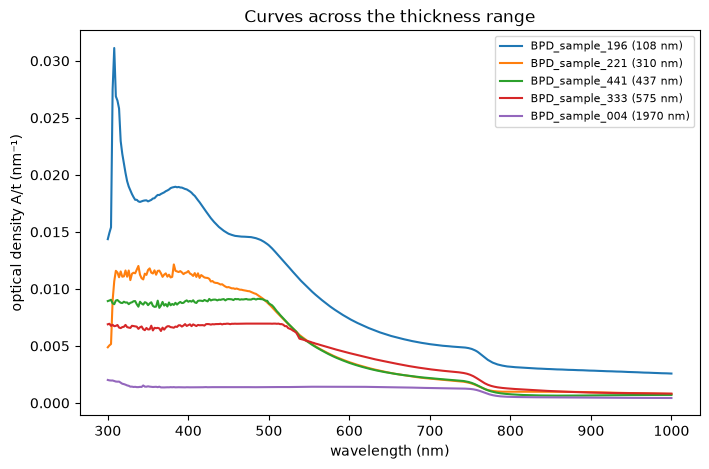

In [7]:
def film_near_thickness(target):
    return (dataset.thickness_nm - target).abs().idxmin()

quartiles = dataset.thickness_nm.quantile([0.0, 0.25, 0.5, 0.75, 1.0])

plt.figure(figsize=(8, 5))
for target in quartiles:
    sample_id = film_near_thickness(target)
    row = curves.sample_ids.get_loc(sample_id)
    plt.plot(wavelengths, values[row],
             label=f"{sample_id} ({dataset.thickness_nm[sample_id]:.0f} nm)")
plt.xlabel("wavelength (nm)")
plt.ylabel("optical density A/t (nm⁻¹)")
plt.title("Curves across the thickness range")
plt.legend(fontsize=8)
plt.show()

The population view: per-wavelength median and interquartile band over all films (NaN-aware, so truncated films still contribute below 900 nm):

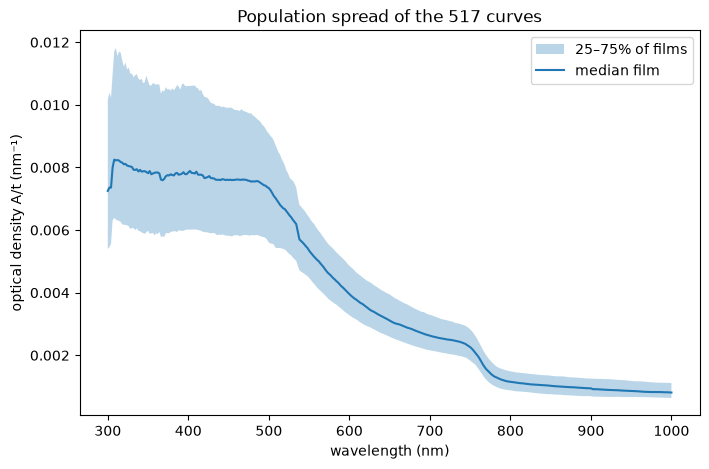

In [8]:
median = np.nanmedian(values, axis=0)
q25, q75 = np.nanpercentile(values, [25, 75], axis=0)

plt.figure(figsize=(8, 5))
plt.fill_between(wavelengths, q25, q75, alpha=0.3, label="25–75% of films")
plt.plot(wavelengths, median, label="median film")
plt.xlabel("wavelength (nm)")
plt.ylabel("optical density A/t (nm⁻¹)")
plt.title("Population spread of the 517 curves")
plt.legend()
plt.show()

## Grid provenance probe

The paper reports spectra acquired at a 10 nm step over 300–900 nm; the archive ships 300–1000 nm at 2 nm.
Were the shipped curves linearly interpolated from 10 nm data, each curve would be exactly straight between consecutive original samples (the interpolation knots, every fifth point of the 2 nm grid) and bend only at them.
The second difference — the discrete measure of curvature — would therefore be zero between knots and non-zero at knots: a period-5 signature that raw 2 nm measurement would not be expected to show.
Grouping the median |second difference| of all films by grid position modulo 5 separates the cases: one dominant phase suggests interpolation; five equal phases indicate measured data.

In [9]:
second = np.abs(np.diff(values, n=2, axis=1))
profile = np.nanmedian(second, axis=0)  # one value per interior point
phase = np.array([profile[phase::5].mean() for phase in range(5)])
pd.Series(phase, index=pd.Index(range(5), name="grid position mod 5"),
          name="median |second difference| (nm⁻¹)").to_frame()

,median |second difference| (nm⁻¹)
grid position mod 5,
0,0.000032
1,0.000032
2,0.000033
3,0.000033
4,0.000031


## Parameter distributions

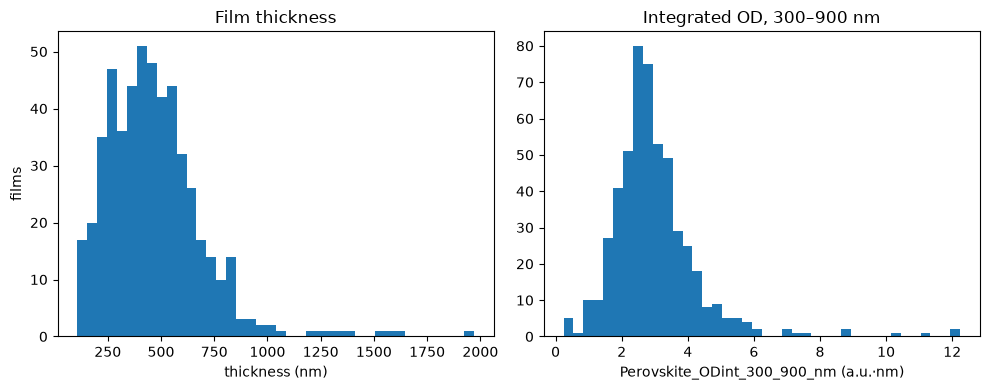

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(dataset.thickness_nm, bins=40)
axes[0].set_xlabel("thickness (nm)"); axes[0].set_ylabel("films")
axes[0].set_title("Film thickness")
axes[1].hist(dataset.parameters[ODINT_PRIMARY], bins=40)
axes[1].set_xlabel(f"{ODINT_PRIMARY} (a.u.·nm)")
axes[1].set_title("Integrated OD, 300–900 nm")
fig.tight_layout()
plt.show()

Category structure of the fabrication variables. This is the population the models would be asked to reproduce:

In [11]:
for column in [
    SUBSTRATE_STACK_COLUMN,
    "Perovskite_synthesis_solvents",
    "Perovskite_synthesis_additives_surfactants",
    "Perovskite_deposition_blade_speed_mm_s",
]:
    counts = dataset.parameters[column].value_counts()
    print(f"\n{column}: {len(counts)} distinct values")
    print(counts.head(10).to_string())


Substrate_stack_sequence: 4 distinct values
Substrate_stack_sequence
glass                       313
corning                     191
glass / TiO2-c / TiO2-mp      8
FTO / TiO2-c                  5

Perovskite_synthesis_solvents: 1 distinct values
Perovskite_synthesis_solvents
ME/ACN    517

Perovskite_synthesis_additives_surfactants: 3 distinct values
Perovskite_synthesis_additives_surfactants
NaLES/DDABr    202
none           169
NaLES          146

Perovskite_deposition_blade_speed_mm_s: 17 distinct values
Perovskite_deposition_blade_speed_mm_s
40     262
60      84
50      53
100     30
90      21
70      14
80       9
110      8
30       6
20       6


Fabrication dates span the measurement campaign. Films per month show whether the campaign was one continuous run or several batches.

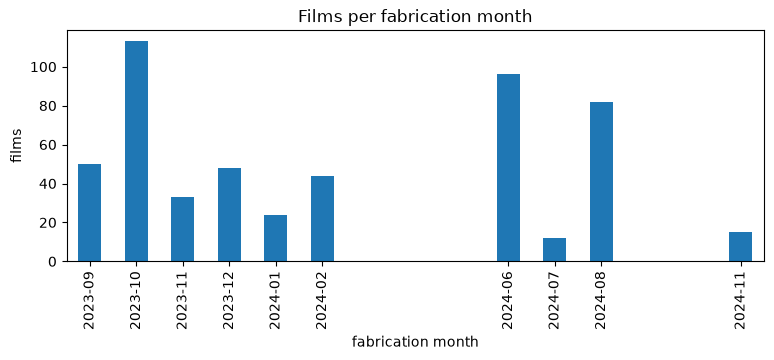

In [12]:
dates = pd.to_datetime(dataset.parameters[DATE_COLUMN],
                       format="%d/%m/%Y", errors="coerce")
per_month = dates.dt.to_period("M").value_counts().sort_index()
ax = per_month.plot(kind="bar", figsize=(9, 3))
ax.set_xlabel("fabrication month"); ax.set_ylabel("films")
ax.set_title("Films per fabrication month")
plt.show()

## The ODint < 2 label

The source paper treats an integrated OD below 2 a.u. as a low-quality indicator. We keep those films as a subgroup for now rather than filter them out.

86 films below the ODint < 2 a.u. label


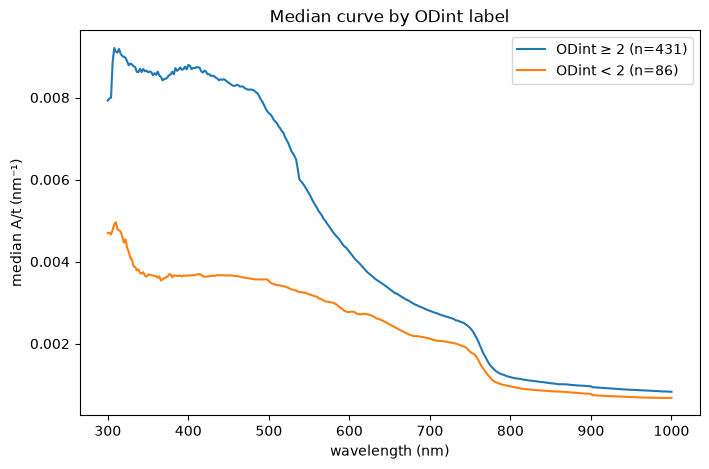

In [13]:
low = (dataset.parameters[ODINT_PRIMARY] < 2).to_numpy()
print(f"{low.sum()} films below the ODint < 2 a.u. label")

median_low = np.nanmedian(values[low], axis=0)
median_rest = np.nanmedian(values[~low], axis=0)

plt.figure(figsize=(8, 5))
plt.plot(wavelengths, median_rest, label=f"ODint ≥ 2 (n={int((~low).sum())})")
plt.plot(wavelengths, median_low, label=f"ODint < 2 (n={int(low.sum())})")
plt.xlabel("wavelength (nm)"); plt.ylabel("median A/t (nm⁻¹)")
plt.title("Median curve by ODint label")
plt.legend()
plt.show()

## How many independent directions does the population have?

Neighbouring wavelengths on a 2 nm grid are strongly correlated, so
the 301-dimensional 300–900 nm span is far from 301 independent
numbers. The PCA spectrum shows how many directions actually carry
the population's variability — written down here, before any
generative modelling, as the baseline any model must beat: a compact
linear representation is expected to capture most of it.

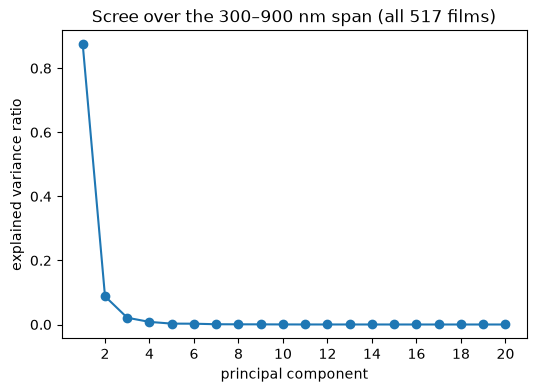

2 components reach 90% of the variance
4 components reach 99% of the variance


In [14]:
complete = values[:, wavelengths <= 900]  # all 517 films are complete here
ratios = pca_explained_variance(complete)

plt.figure(figsize=(6, 4))
plt.plot(np.arange(1, 21), ratios[:20], marker="o")
plt.xlabel("principal component")
plt.ylabel("explained variance ratio")
plt.title("Scree over the 300–900 nm span (all 517 films)")
plt.gca().xaxis.set_major_locator(mticker.MultipleLocator(2))
plt.show()

cumulative = np.cumsum(ratios)
for level in (0.90, 0.99):
    components = int(np.searchsorted(cumulative, level)) + 1
    print(f"{components} components reach {level:.0%} of the variance")

## Curve diversity

How close is every curve to its nearest neighbour? The nearest-neighbour distance distribution is a diversity estimate, and its lower end doubles as a near-duplicate check (two nearly identical films would stand out near zero).

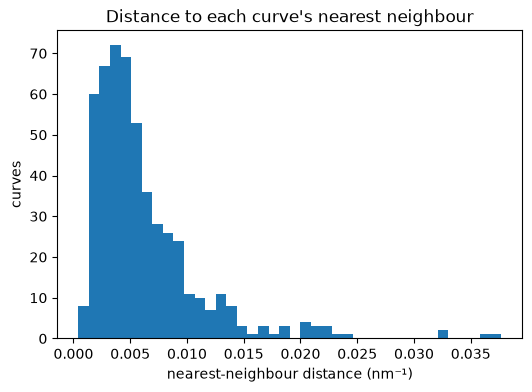

closest pair: BPD_sample_294 ↔ BPD_sample_296 at 4.26e-04 nm⁻¹
median 4.89e-03 nm⁻¹, 5th percentile 1.67e-03 nm⁻¹


In [15]:
distances, neighbours = nearest_neighbour_distances(complete)

plt.figure(figsize=(6, 4))
plt.hist(distances, bins=40)
plt.xlabel("nearest-neighbour distance (nm⁻¹)")
plt.ylabel("curves")
plt.title("Distance to each curve's nearest neighbour")
plt.show()

i = int(distances.argmin())
j = int(neighbours[i])
print(f"closest pair: {curves.sample_ids[i]} ↔ {curves.sample_ids[j]} "
      f"at {distances[i]:.2e} nm⁻¹")
print(f"median {np.median(distances):.2e} nm⁻¹, "
      f"5th percentile {np.percentile(distances, 5):.2e} nm⁻¹")

## Can the paper's modelling subset be reproduced?

The source paper builds a 245-film modelling subset in two steps (its §2.3): first drop films with a missing target integrated OD, then exclude additive categories "with too few observations", without stating what "too few" means.
Step one removes nothing here (all 517 films have complete ODint values), so the reconstruction hinges entirely on the unstated threshold of step two.

The additive chemistry takes exactly three values in the shipped database: NaLES/DDABr (202 films), none (169) and NaLES (146). In experimental-design language, each recipe is one *arm* of the campaign.
The rule "exclude arms with too few observations" keeps a film only if its arm holds at least the threshold's number of films, so it can only remove whole arms at a time.
The sweep below probes both plausible small thresholds (2–100, all far below the smallest arm, so they exclude nothing) and the three boundary values (147, 170, 203 — just above each arm's size, where the arms drop out one by one).
Because arms come in chunks of 146, 169 and 202 films, the only reachable subset sizes are {517, 371, 202, 0}. The published 245 falls in none of these plateaus, so the stated filter cannot reproduce the paper's subset from the shipped database. It must have been applied to a different version of the data, or its description is incomplete.
Recorded as a provenance limitation in the audit report.

In [16]:
arm_counts = dataset.parameters[ADDITIVES_COLUMN].value_counts()
print(arm_counts.to_string())

thresholds = [2, 5, 10, 20, 50, 100, 147, 170, 203]
sizes = {
    threshold: len(subset_min_observations(dataset.parameters, ADDITIVES_COLUMN, threshold))
    for threshold in thresholds
}
pd.Series(sizes, name="films kept").to_frame()

Perovskite_synthesis_additives_surfactants
NaLES/DDABr    202
none           169
NaLES          146


,films kept
2,517
5,517
10,517
20,517
50,517
100,517
147,371
170,202
203,0


## Findings

The audit ran over the full archive. The machine-readable numbers behind these findings live in
[`../reports/qc_summary.json`](../reports/qc_summary.json) and
[`../reports/curve_diagnostics.csv`](../reports/curve_diagnostics.csv),
regenerated with `python scripts/write_qc_report.py`.

**Missingness is one structural pattern.**
Of the 181,467 grid points (517 films × 351 wavelengths), 2,400 (1.3%) are unmeasured, and every one belongs to the 48 films whose curves stop at exactly 900 nm, 50 trailing points each.
No film starts late, has an interior hole, or is empty. Over 300–900 nm the population is complete (517 curves); over the shipped 300–1000 nm grid it is 469.

**Values are plausible without intervention.**
No negative values (minimum 1.14×10⁻⁴ nm⁻¹), no constant and no all-zero curves. No clipping or cleaning policy is needed for this archive.

**The curves carry no 10 nm resampling signature.**
The median absolute second difference, split by grid position modulo 5, is flat across phases (0.000031–0.000033 nm⁻¹).
Piecewise-linear interpolation from a 10 nm grid would knot every fifth point, which it does not.
A smoothed resampling would leave no knots, so the possibility stays open. Operationally, the curves behave as continuous 2 nm data.

**Parameters are complete where the analysis needs them.**
All 517 films have all five integrated-OD windows, a positive measured thickness (107.5–1970.5 nm), and a "curve evaluated" flag that agrees with the curves everywhere.
All fabrication dates parse, spanning 2023-09 to 2024-11.

**The population is coherent and variable.**
One composition, one solvent system; genuine variation across additives (NaLES/DDABr 202, none 169, NaLES 146), substrates (glass 313, corning 191, TiO₂-based
13), blade speed (17 values, 40 mm/s most common at 262 films), and a ~14-month fabrication campaign.
86 films (~17%) fall below the source paper's low-quality threshold of `ODint < 2` a.u. They are kept, with the label recorded as a subgroup flag. No film is dropped at this point.

**The population is strikingly low-dimensional.**
Across the 301-dimensional 300–900 nm span, a single principal component carries 87% of the variance; two reach 96% cumulatively and four reach 99%.
Neighbouring-wavelength correlation concentrates the variability into a handful of shape directions — recorded here before any generative modelling, because it predicts that a compact linear model will be a very strong baseline.

**No two curves are twins.**
The median nearest-neighbour distance between curves is 4.9×10⁻³ nm⁻¹, roughly half of a typical curve's peak amplitude, so the population is genuinely diverse.
The closest pair (`BPD_sample_294` and `BPD_sample_296`, at 4.3×10⁻⁴ nm⁻¹) is worth a glance as a look-alike pair, but it sits far above zero — no duplicated or double-entered films.

**The paper's 245-film subset cannot be reconstructed from this
archive.**
Its stated construction — drop films with a missing target integrated OD (none here), then exclude additive categories with too few observations — can only ever produce subset sizes {517, 371, 202, 0} from the shipped additive arms of {202, 169, 146} films.
The published 245 is not reachable, so the subset definition cannot be recovered from the shipped database. The audit report records this as a provenance limitation.

Figures in this notebook keep wavelength ascending to match the source publication. Individual plots may invert the axis for reading convenience.
